# BERT Text Classification + T5 Sequence-to-Sequence Generation
By Rohith John (24BAD100)

## Setup

In [1]:
import os
import glob
import json
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    AutoModelForSeq2SeqLM
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

Device: cuda
GPU: Tesla T4


## PART A — Dataset preparation and preprocessing


In [2]:
csv_files=glob.glob("/kaggle/input/**/*.csv", recursive=True)
print("CSV files found:", len(csv_files))
for f in csv_files[:30]: print(f)
if not csv_files: raise FileNotFoundError("Attach an IMDb CSV using Add Input.")

TEXT_CANDIDATES=["review","text","reviews","content","comment"]
LABEL_CANDIDATES=["sentiment","label","class","target"]
selected_path=None; raw_df=None
for path in csv_files:
    try:
        head=pd.read_csv(path,nrows=5)
        cols={c.lower().strip():c for c in head.columns}
        tc=next((cols[x] for x in TEXT_CANDIDATES if x in cols),None)
        lc=next((cols[x] for x in LABEL_CANDIDATES if x in cols),None)
        if tc and lc:
            selected_path=path; raw_df=pd.read_csv(path); break
    except Exception as e: print("Skipping",path,str(e)[:100])
if raw_df is None: raise ValueError("No CSV with recognizable review/text and sentiment/label columns found.")
print("Selected:",selected_path,"\nColumns:",raw_df.columns.tolist())
display(raw_df.head())

CSV files found: 1
/kaggle/input/datasets/rehanliaqat17/imbd-dataset/IMDB_Dataset.csv
Selected: /kaggle/input/datasets/rehanliaqat17/imbd-dataset/IMDB_Dataset.csv 
Columns: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
cols={c.lower().strip():c for c in raw_df.columns}
text_col=next(cols[x] for x in TEXT_CANDIDATES if x in cols)
label_col=next(cols[x] for x in LABEL_CANDIDATES if x in cols)
df=raw_df[[text_col,label_col]].copy()
df.columns=["text","label"]
df=df.dropna()
df["text"]=df["text"].astype(str).str.strip()
df["label"]=df["label"].astype(str).str.strip().str.lower()
df=df[df.text.str.len()>0]

values=sorted(df.label.unique().tolist())
if set(values).issubset({"positive","negative"}): label2id={"negative":0,"positive":1}
elif set(values).issubset({"0","1"}): label2id={"0":0,"1":1}
else: label2id={v:i for i,v in enumerate(values)}
df["labels"]=df.label.map(label2id).astype(int)
id2label={v:k for k,v in label2id.items()}
num_labels=len(label2id)
print("Samples:",len(df),"Label mapping:",label2id)
display(df.label.value_counts().to_frame("count"))

# Set MAX_SAMPLES=None to use every row. A smaller sample is faster for a practical run.
MAX_SAMPLES=8000
if MAX_SAMPLES and len(df)>MAX_SAMPLES:
    df,_=train_test_split(df,train_size=MAX_SAMPLES,random_state=SEED,stratify=df.labels)
train_df,test_df=train_test_split(df[["text","labels"]],test_size=.2,random_state=SEED,stratify=df.labels)
print("Train:",len(train_df),"Test:",len(test_df))

Samples: 50000 Label mapping: {'negative': 0, 'positive': 1}


,count
label,
positive,25000
negative,25000


Train: 6400 Test: 1600


In [4]:
train_ds=Dataset.from_pandas(train_df.reset_index(drop=True))
test_ds=Dataset.from_pandas(test_df.reset_index(drop=True))
BERT_CHECKPOINT="bert-base-uncased"
bert_tokenizer=AutoTokenizer.from_pretrained(BERT_CHECKPOINT)
MAX_LENGTH=256

def tokenize_batch(batch):
    return bert_tokenizer(batch["text"],truncation=True,padding=False,max_length=MAX_LENGTH)

train_tok=train_ds.map(tokenize_batch,batched=True)
test_tok=test_ds.map(tokenize_batch,batched=True)
train_tok=train_tok.select_columns(["input_ids","attention_mask","labels"])
test_tok=test_tok.select_columns(["input_ids","attention_mask","labels"])
collator=DataCollatorWithPadding(tokenizer=bert_tokenizer)
print("Tokenized example:",train_tok[0].keys())

Map:   0%|          | 0/6400 [00:00<?, ? examples/s]

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Tokenized example: dict_keys(['input_ids', 'attention_mask', 'labels'])


## PART B — Fine-tuning BERT for text classification

In [6]:
import inspect

bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_CHECKPOINT,
    num_labels=num_labels,
    id2label={int(k): str(v) for k, v in id2label.items()},
    label2id={str(k): int(v) for k, v in label2id.items()}
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    p, r, f, _ = precision_recall_fscore_support(
        labels, preds, average="weighted", zero_division=0
    )

    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": p,
        "recall": r,
        "f1": f
    }

params = inspect.signature(TrainingArguments.__init__).parameters

eval_name = (
    "eval_strategy"
    if "eval_strategy" in params
    else "evaluation_strategy"
)

kwargs = dict(
    output_dir="/kaggle/working/bert_results",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=2,
    weight_decay=0.01,
    logging_steps=50,
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    report_to="none",
    fp16=torch.cuda.is_available(),
    seed=SEED
)

kwargs[eval_name] = "epoch"

args = TrainingArguments(**kwargs)

trainer = Trainer(
    model=bert_model,
    args=args,
    train_dataset=train_tok,
    eval_dataset=test_tok,
    tokenizer=bert_tokenizer,
    data_collator=collator,
    compute_metrics=compute_metrics
)

trainer.train()

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipykernel_311/4157322704.py:54: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.251400,0.246720,0.897500,0.897801,0.897500,0.897481
2,0.179400,0.403160,0.912500,0.912758,0.912500,0.912486


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


TrainOutput(global_step=800, training_loss=0.255809828042984, metrics={'train_runtime': 439.5011, 'train_samples_per_second': 29.124, 'train_steps_per_second': 1.82, 'total_flos': 1683910754304000.0, 'train_loss': 0.255809828042984, 'epoch': 2.0})

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Evaluation metrics:
eval_loss: 0.4032
eval_accuracy: 0.9125
eval_precision: 0.9128
eval_recall: 0.9125
eval_f1: 0.9125
eval_runtime: 16.7754
eval_samples_per_second: 95.3780
eval_steps_per_second: 5.9610
epoch: 2.0000


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


              precision    recall  f1-score   support

    negative       0.92      0.90      0.91       800
    positive       0.90      0.93      0.91       800

    accuracy                           0.91      1600
   macro avg       0.91      0.91      0.91      1600
weighted avg       0.91      0.91      0.91      1600



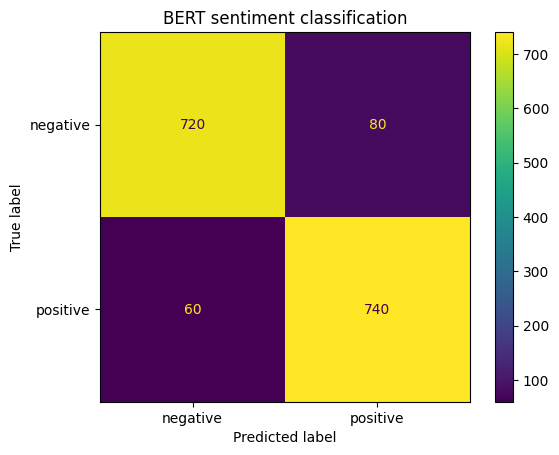

In [7]:
eval_results=trainer.evaluate()
print("Evaluation metrics:")
for k,v in eval_results.items():
    if isinstance(v,(int,float)): print(f"{k}: {v:.4f}")
pred=trainer.predict(test_tok)
y_true=pred.label_ids; y_pred=np.argmax(pred.predictions,axis=1)
names=[str(id2label[i]) for i in range(num_labels)]
print(classification_report(y_true,y_pred,target_names=names,zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_true,y_pred),display_labels=names).plot(values_format="d")
plt.title("BERT sentiment classification"); plt.show()

In [8]:
def predict_sentiment(texts):
    bert_model.to(DEVICE); bert_model.eval()
    inputs=bert_tokenizer(texts,return_tensors="pt",truncation=True,padding=True,max_length=MAX_LENGTH).to(DEVICE)
    with torch.no_grad():
        probs=torch.softmax(bert_model(**inputs).logits,dim=-1).cpu().numpy()
    ids=probs.argmax(axis=1)
    return pd.DataFrame([{"text":t,"predicted_label":id2label[int(i)],"confidence":round(float(probs[n,i]),4)}
                         for n,(t,i) in enumerate(zip(texts,ids))])

samples=["This movie was wonderful. The acting and story were excellent.",
         "The film was boring, poorly written, and a complete waste of time."]
display(predict_sentiment(samples))

BERT_SAVE="/kaggle/working/fine_tuned_bert_imdb"
trainer.save_model(BERT_SAVE); bert_tokenizer.save_pretrained(BERT_SAVE)
print("BERT saved:",BERT_SAVE)

,text,predicted_label,confidence
0,This movie was wonderful. The acting and story...,positive,0.9988
1,"The film was boring, poorly written, and a com...",negative,0.9987


BERT saved: /kaggle/working/fine_tuned_bert_imdb


## PART C — Sequence-to-sequence text generation using T5-small
T5 is an encoder-decoder Transformer. This section uses the pretrained model for summarization inference; it does not fine-tune T5.

In [9]:
T5_CHECKPOINT="t5-small"
t5_tokenizer=AutoTokenizer.from_pretrained(T5_CHECKPOINT)
t5_model=AutoModelForSeq2SeqLM.from_pretrained(T5_CHECKPOINT).to(DEVICE)
t5_model.eval()

def generate_summary(text,max_input_length=512,max_output_length=100,num_beams=4):
    prompt="summarize: "+text
    inputs=t5_tokenizer(prompt,return_tensors="pt",truncation=True,max_length=max_input_length).to(DEVICE)
    with torch.no_grad():
        output=t5_model.generate(**inputs,max_length=max_output_length,num_beams=num_beams,early_stopping=True)
    return t5_tokenizer.decode(output[0],skip_special_tokens=True)

sample_text=("The city council has announced a new public transport plan. The plan will add electric buses, "
             "improve bus frequency during peak hours, and introduce digital ticketing. Officials expect "
             "the changes to reduce traffic congestion and air pollution over the next two years.")
print("INPUT:",sample_text)
print("\nGENERATED SUMMARY:",generate_summary(sample_text))

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/242M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

INPUT: The city council has announced a new public transport plan. The plan will add electric buses, improve bus frequency during peak hours, and introduce digital ticketing. Officials expect the changes to reduce traffic congestion and air pollution over the next two years.

GENERATED SUMMARY: the city council has announced a new public transport plan. the plan will add electric buses, improve bus frequency during peak hours, and introduce digital ticketing.


In [10]:
examples=[
 "Artificial intelligence is being used in healthcare to assist doctors with medical image analysis, patient monitoring, and treatment planning.",
 "A university has introduced a recycling programme that separates paper, plastic, and electronic waste. Students can use collection points across campus."
]
rows=[]
for text in examples:
    for beams in [2,4]:
        rows.append({"input_text":text,"num_beams":beams,
                     "generated_output":generate_summary(text,max_output_length=80,num_beams=beams)})
generation_df=pd.DataFrame(rows)
display(generation_df)
GENERATION_CSV="/kaggle/working/t5_generated_outputs.csv"
generation_df.to_csv(GENERATION_CSV,index=False)
T5_SAVE="/kaggle/working/t5_small"
t5_model.save_pretrained(T5_SAVE); t5_tokenizer.save_pretrained(T5_SAVE)
print("Generated outputs:",GENERATION_CSV)
print("T5 saved:",T5_SAVE)

,input_text,num_beams,generated_output
0,Artificial intelligence is being used in healt...,2,artificial intelligence is being used in healt...
1,Artificial intelligence is being used in healt...,4,artificial intelligence is being used in healt...
2,A university has introduced a recycling progra...,2,a university has introduced a recycling progra...
3,A university has introduced a recycling progra...,4,a university has introduced a recycling progra...


Generated outputs: /kaggle/working/t5_generated_outputs.csv
T5 saved: /kaggle/working/t5_small


## PART D — Model testing and output analysis

In [11]:
comparison_reviews=[
 "An engaging movie with excellent performances and a touching story.",
 "The movie was dull, confusing, and disappointing from beginning to end."
]
comparison=predict_sentiment(comparison_reviews)
comparison["t5_generated_text"]=[generate_summary(x,max_output_length=60,num_beams=4) for x in comparison_reviews]
display(comparison)

print("BERT metrics:")
for metric in ["eval_accuracy","eval_precision","eval_recall","eval_f1"]:
    if metric in eval_results: print(f"{metric}: {eval_results[metric]:.4f}")

observations={
 "dataset_file":selected_path,"samples_used":int(len(df)),"number_of_classes":int(num_labels),
 "bert_metrics":{k:float(v) for k,v in eval_results.items() if k in ["eval_accuracy","eval_precision","eval_recall","eval_f1"]},
 "bert_model_path":BERT_SAVE,"t5_model_path":T5_SAVE,"generated_outputs_csv":GENERATION_CSV
}
with open("/kaggle/working/experiment_observations.json","w") as f: json.dump(observations,f,indent=2)
print(json.dumps(observations,indent=2))

,text,predicted_label,confidence,t5_generated_text
0,An engaging movie with excellent performances ...,positive,0.9990,an engaging movie with excellent performances ...
1,"The movie was dull, confusing, and disappointi...",negative,0.9988,"the movie was dull, confusing, and disappointi..."


BERT metrics:
eval_accuracy: 0.9125
eval_precision: 0.9128
eval_recall: 0.9125
eval_f1: 0.9125
{
  "dataset_file": "/kaggle/input/datasets/rehanliaqat17/imbd-dataset/IMDB_Dataset.csv",
  "samples_used": 8000,
  "number_of_classes": 2,
  "bert_metrics": {
    "eval_accuracy": 0.9125,
    "eval_precision": 0.9127579737335836,
    "eval_recall": 0.9125,
    "eval_f1": 0.9124863259884357
  },
  "bert_model_path": "/kaggle/working/fine_tuned_bert_imdb",
  "t5_model_path": "/kaggle/working/t5_small",
  "generated_outputs_csv": "/kaggle/working/t5_generated_outputs.csv"
}


## Expected outcome and notes
- IMDb text data is loaded directly from Kaggle's `/kaggle/input` mount.
- BERT is fine-tuned for sentiment classification and evaluated using accuracy, precision, recall, and F1-score.
- T5-small generates summaries from sample text using sequence-to-sequence generation.
- Model files, generated text, and observations are saved under `/kaggle/working/`.

Record the actual metrics and generated outputs from your run. Results depend on the dataset, GPU, sample count, and training epochs. If you get an out-of-memory error, reduce batch size from 8 to 4 and/or reduce `MAX_SAMPLES`.